# 02 · Pipeline y comparación de modelos (Producto 1)
**Métrica principal: PR-AUC (average precision).** El objetivo es **ordenar** a los clientes para que el call center llame primero a los más probables. Con solo 11 % de positivos, el ROC-AUC se ve optimista; la PR-AUC mide directamente qué tan "limpia" es la lista de llamadas. Un modelo al azar tiene PR-AUC ≈ 0,11.

Reportamos también **ROC-AUC**, **recall** y **precisión**.

In [1]:
!pip install -q optuna lightgbm

In [2]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Datos: Bank Marketing (UCI, id 222, archivo bank-additional-full.csv), copia pública en GitHub.
# Plan B: descarguen bank-additional-full.csv desde UCI y súbanlo al panel Archivos de Colab.
URL = "https://raw.githubusercontent.com/selva86/datasets/master/bank-full.csv"

NOMBRES = {
    "age": "edad", "job": "ocupacion", "marital": "estado_civil", "education": "educacion",
    "default": "en_mora", "housing": "hipoteca", "loan": "prestamo", "contact": "tipo_contacto",
    "month": "mes", "day_of_week": "dia_semana", "duration": "duracion_llamada",
    "campaign": "contactos_campana", "pdays": "dias_ultimo_contacto", "previous": "contactos_previos",
    "poutcome": "resultado_previo", "emp.var.rate": "tasa_var_empleo", "cons.price.idx": "ipc",
    "cons.conf.idx": "confianza_consumidor", "euribor3m": "euribor3m", "nr.employed": "num_empleados"}

NUMERICAS = ["edad", "contactos_campana", "dias_ultimo_contacto", "contactos_previos",
             "tasa_var_empleo", "ipc", "confianza_consumidor", "euribor3m", "num_empleados"]
CATEGORICAS = ["ocupacion", "estado_civil", "educacion", "en_mora", "hipoteca", "prestamo",
               "tipo_contacto", "mes", "dia_semana", "resultado_previo"]
# duracion_llamada NO entra al modelo: solo se conoce DESPUÉS de la llamada (fuga de datos).

def cargar_datos():
    try:
        df = pd.read_csv(URL, sep=";")
    except Exception:
        df = pd.read_csv("bank-additional-full.csv", sep=";")
    df = df.rename(columns=NOMBRES)
    # 999 significa "nunca fue contactado": no es una cantidad, lo convertimos en faltante
    df["dias_ultimo_contacto"] = df["dias_ultimo_contacto"].replace(999, np.nan)
    df["suscribe"] = (df["y"].str.strip() == "yes").astype(int)
    return df.drop(columns="y")

df = cargar_datos()
X, y = df[NUMERICAS + CATEGORICAS], df["suscribe"]
print(df.shape, f"| suscriben: {y.mean():.1%}")

(41188, 21) | suscriben: 11.3%


In [3]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Misma división en todos los notebooks: el test se usa una sola vez, al final
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def preprocesador():
    # add_indicator=True crea la columna "nunca fue contactado" a partir de los 999
    num = Pipeline([("imputar", SimpleImputer(strategy="median", add_indicator=True)),
                    ("escalar", StandardScaler())])
    # "unknown" se mantiene como categoría propia: no saber si tiene mora también informa
    cat = Pipeline([("onehot", OneHotEncoder(handle_unknown="ignore"))])
    return ColumnTransformer([("num", num, NUMERICAS), ("cat", cat, CATEGORICAS)])

## Los 5 modelos, con validación cruzada estratificada de 5 folds

In [4]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier

modelos = {
    "Baseline (clase mayoritaria)": DummyClassifier(),
    "Regresión logística (L2)": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "k-NN (k = 25)": KNeighborsClassifier(n_neighbors=25),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced",
                                            random_state=42, n_jobs=-1),
    "LightGBM": LGBMClassifier(class_weight="balanced", random_state=42, verbose=-1),
}
metricas = {"pr_auc": "average_precision", "roc_auc": "roc_auc", "recall": "recall", "precision": "precision"}
filas = []
for nombre, m in modelos.items():
    r = cross_validate(Pipeline([("prep", preprocesador()), ("modelo", m)]), X_tr, y_tr, cv=cv, scoring=metricas)
    fila = {"modelo": nombre}
    for k in metricas:
        fila[k] = f"{r['test_' + k].mean():.3f} ± {r['test_' + k].std():.3f}"
    fila["_pr"] = r["test_pr_auc"].mean()
    filas.append(fila)
tabla = pd.DataFrame(filas).sort_values("_pr")
mejor_nombre = tabla.iloc[-1]["modelo"]
tabla.drop(columns="_pr").reset_index(drop=True)

,modelo,pr_auc,roc_auc,recall,precision
0,Baseline (clase mayoritaria),0.113 ± 0.000,0.500 ± 0.000,0.000 ± 0.000,0.000 ± 0.000
1,k-NN (k = 25),0.412 ± 0.008,0.766 ± 0.008,0.242 ± 0.014,0.632 ± 0.014
2,Regresión logística (L2),0.444 ± 0.009,0.790 ± 0.005,0.623 ± 0.006,0.350 ± 0.006
3,LightGBM,0.463 ± 0.010,0.791 ± 0.004,0.617 ± 0.007,0.379 ± 0.004
4,Random Forest,0.464 ± 0.010,0.790 ± 0.004,0.607 ± 0.013,0.394 ± 0.006


## ¿Y si hubiéramos usado la duración de la llamada?
Misma regresión logística, agregando `duracion_llamada`. Así se ve una fuga de datos: el número sube mucho, pero el modelo **no se puede usar**, porque nadie sabe cuánto durará una llamada antes de hacerla.

In [5]:
from sklearn.base import clone
X_fuga = df.loc[X_tr.index, NUMERICAS + CATEGORICAS + ["duracion_llamada"]]
prep_fuga = ColumnTransformer([
    ("num", preprocesador().transformers[0][1], NUMERICAS + ["duracion_llamada"]),
    ("cat", preprocesador().transformers[1][1], CATEGORICAS)])
for nombre, prep, datos in [("Con duración (fuga)", prep_fuga, X_fuga), ("Sin duración (honesto)", preprocesador(), X_tr)]:
    s = cross_val_score(Pipeline([("prep", prep), ("modelo", LogisticRegression(max_iter=2000, class_weight="balanced"))]),
                        datos, y_tr, cv=cv, scoring="average_precision")
    print(f"{nombre:<24} PR-AUC = {s.mean():.3f} ± {s.std():.3f}")

Con duración (fuga)      PR-AUC = 0.581 ± 0.021


Sin duración (honesto)   PR-AUC = 0.444 ± 0.009


## Elección del modelo y evaluación final en el test (una sola vez)

Mejor modelo por PR-AUC en validación cruzada: Random Forest


Test · PR-AUC = 0.490 · ROC-AUC = 0.808 · recall = 0.638 · precisión = 0.420
Llamando al 10 % con mayor probabilidad: alcanzamos el 48% de los suscriptores y la tasa de éxito sube de 11% a 54%


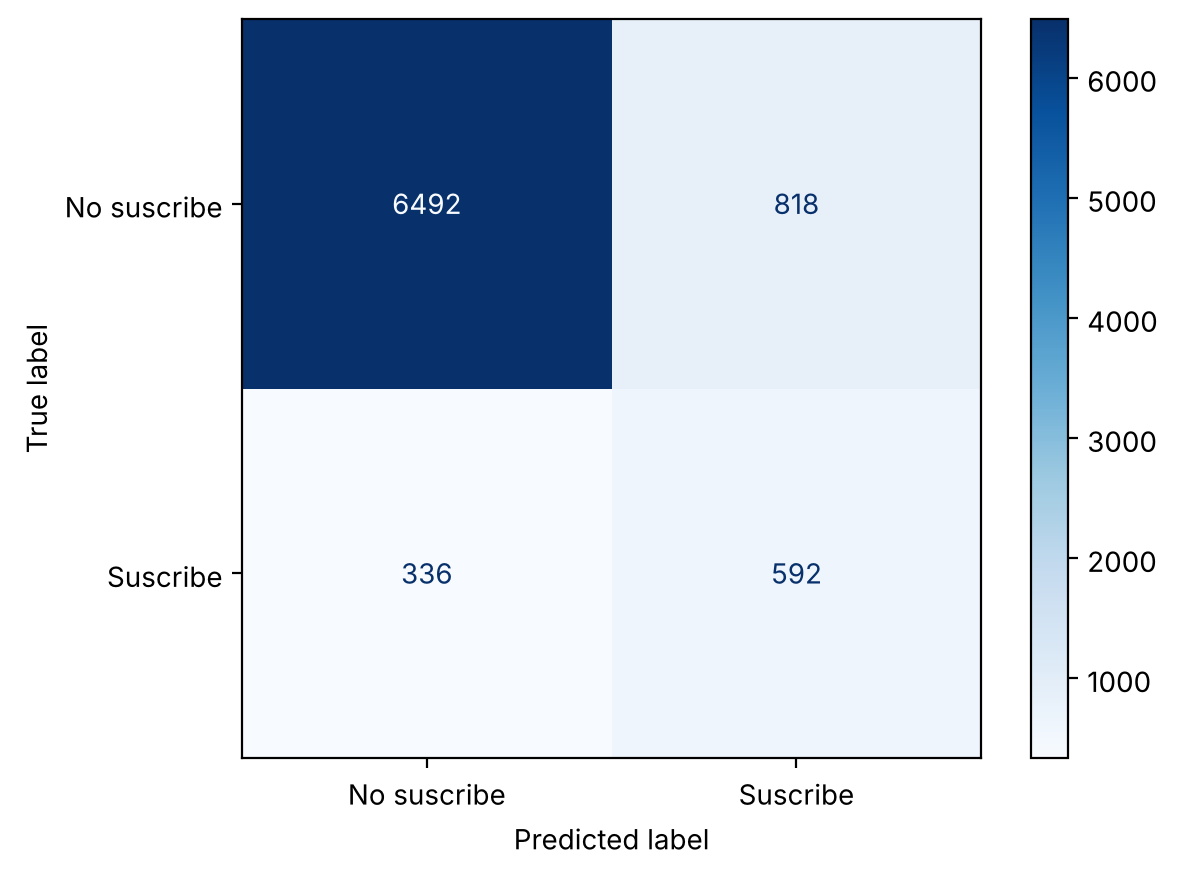

In [6]:
from sklearn.metrics import average_precision_score, roc_auc_score, recall_score, precision_score, ConfusionMatrixDisplay
print("Mejor modelo por PR-AUC en validación cruzada:", mejor_nombre)
mejor = Pipeline([("prep", preprocesador()), ("modelo", modelos[mejor_nombre])]).fit(X_tr, y_tr)
prob = mejor.predict_proba(X_te)[:, 1]
pred = mejor.predict(X_te)
print(f"Test · PR-AUC = {average_precision_score(y_te, prob):.3f} · ROC-AUC = {roc_auc_score(y_te, prob):.3f} · "
      f"recall = {recall_score(y_te, pred):.3f} · precisión = {precision_score(y_te, pred):.3f}")

# Lectura de negocio: si llamamos solo al 10 % con mayor probabilidad, ¿qué parte de los suscriptores alcanzamos?
orden = np.argsort(-prob); top = orden[: int(0.10 * len(prob))]
print(f"Llamando al 10 % con mayor probabilidad: alcanzamos el {y_te.values[top].sum() / y_te.sum():.0%} "
      f"de los suscriptores y la tasa de éxito sube de {y_te.mean():.0%} a {y_te.values[top].mean():.0%}")
ConfusionMatrixDisplay.from_predictions(y_te, pred, display_labels=["No suscribe", "Suscribe"], cmap="Blues")
plt.show()

## Conclusión
- **Random Forest** (PR-AUC 0,464 ± 0,010) y **LightGBM** (0,463 ± 0,010) quedan prácticamente empatados; la regresión logística queda algo detrás (0,444) y k-NN último (0,412). Todos superan claramente al baseline (0,113).
- La **accuracy no aparece** a propósito: el baseline tendría ~89 % sin detectar a nadie.
- **Fuga de datos:** agregar `duracion_llamada` sube la PR-AUC de 0,444 a 0,581, pero ese modelo es inútil en la práctica.
- **En el test** (una sola vez), Random Forest logra PR-AUC = 0,490 y ROC-AUC = 0,808. Llamando solo al 10 % de clientes con mayor probabilidad, el banco alcanza al **48 % de los suscriptores** con una tasa de éxito del **54 %**, frente al 11 % de llamar al azar.

**Para el Producto 2:** optimizar LightGBM con Optuna y comprobar fold a fold si supera a Random Forest.